# A brief tutorial 

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pynav.agents import QAgent
from pynav.environment import Environment as Env

## Data Loading

In [2]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path

n_thr = 3e-6 
data[data < n_thr] = 0.0


In [3]:
print(data.max())

0.0014944219105691057


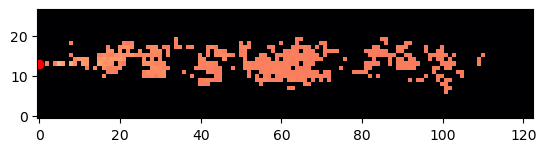

In [4]:
log_data = data.copy()
log_data[log_data == 0.0] = 1e-20

fig, ax = plt.subplots()
ax.imshow(np.log10(log_data[0, :, :]), cmap='magma', origin='lower', vmax=log_data.max())
ax.plot(0.0, 13.0, 'o', c='red')


We can instantiate the an agent as follows

In [5]:
source_position = np.array([20, 0])
source_radius = 2
velocity = 1
rewards = (1.0, -0.001)

env = Env(data = data, 
          source_position=np.array([13, 0]), 
          source_radius = source_radius, 
          bounds = np.array([[-10, 100], [-10, 500]]),
          boundary_conditions = None,
          rewards = rewards)

In [6]:
actions = {
    0 : np.asarray([ 1, 0], dtype=np.int32), 
    1 : np.asarray([-1, 0], dtype=np.int32), 
    2 : np.asarray([0,  1], dtype=np.int32), 
    3 : np.asarray([0, -1], dtype=np.int32), 
}

action_labels = ['up', 'down', 'right', 'left']


initial position will be sampled in the blue region

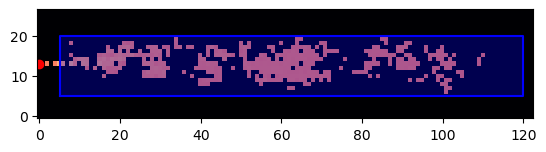

In [7]:
log_data = data.copy()
log_data[log_data == 0.0] = 1e-20

fig, ax = plt.subplots()
ax.imshow(np.log10(log_data[0, :, :]), cmap='magma', origin='lower', vmax=log_data.max())
ax.plot(0.0, 13.0, 'o', c='red')
square_vertices = [(5, 5), (5, 20), (120, 20), (120, 5)]

# Extract x and y coordinates of the vertices
x, y = zip(*square_vertices)

# Plot the square
ax.plot(x + (x[0],), y + (y[0],), 'b-')  # 'b-' for blue line
ax.fill(x, y, 'blue', alpha=0.3)  # Fill the square with blue color with transparency


In [8]:
#self.init_value * np.exp(-self.decay * self.num_episode)
eps_decay = 0.0005
alpha_decay = 0.0001
eps = lambda t :  np.exp(-eps_decay * t) # if np.exp(-eps_decay * t) > 0.001 else 0.001
alpha = lambda t : 0.1 * np.exp(-alpha_decay * t)  

agent = QAgent(
    number_of_actions = 4,
    time_discretization_size = 100,
    memory_size = 5,
    eps_greedy = eps,
    gamma = 1.0,
    learning_rate = alpha,
    s_thr = 3e-6
)

In [9]:
H = 500 # horizon
num_episodes = 20000
rnd_state = np.random.RandomState(12131415)
q_prev = None
cumulative_rewards = []
average_crewards = []
num_steps = []
delta_size = 500
for k in range(num_episodes):
    # Initialization
    agent.reset()
    pos = np.array([rnd_state.randint(5, 20, size=1)[0], rnd_state.randint(5, 110, size=1)[0] ])
    time_idx = rnd_state.randint(0, env.MAX_T)
    obs = env.get_observation(pos, time_idx)
    time_idx = (time_idx + 1) % env.MAX_T
    s = agent.update_state(obs) # update memory and compute olfactory state
    trace = []
    if q_prev is None:
        q_prev = agent.Q.copy()
    c_reward = 0.0
    for t in range(H):
        a = agent.select_action()
        pos, r, terminated = env.make_move(pos, actions[a])
        obs = env.get_observation(pos, time_idx)
        time_idx = (time_idx + 1) % env.MAX_T
        s_prime = agent.update_state(obs)
        c_reward += r * (agent.gamma**t) if t > 0 else r
        trace.append((s, a, s_prime, r))
        if terminated:
            break
        s = s_prime
        num_steps.append(t + 1)
    agent.update_q(trace)
    cumulative_rewards.append(c_reward)
    q_prev = agent.Q.copy()
    if len(cumulative_rewards) >= delta_size:
        print("[{}/{}] avg crew = {}\tsteps = {}\teps = {}\talpha = {}".format(k, num_episodes, np.mean(cumulative_rewards[-delta_size:]), np.mean(num_steps[-delta_size:]), agent.eps_greedy(agent.num_episode), agent.learning_rate(agent.num_episode) ))
        average_crewards.append(np.mean(cumulative_rewards[-delta_size:]))

[499/20000] avg crew = -0.42847200000000024	steps = 250.5	eps = 0.7788007830714049	alpha = 0.09512294245007141
[500/20000] avg crew = -0.4255580000000002	steps = 250.5	eps = 0.778411480013744	alpha = 0.09511343063142526
[501/20000] avg crew = -0.4255580000000002	steps = 250.5	eps = 0.7780223715589573	alpha = 0.09510391976391341
[502/20000] avg crew = -0.4255580000000002	steps = 250.5	eps = 0.7776334576097675	alpha = 0.09509440984744078
[503/20000] avg crew = -0.4255580000000002	steps = 250.5	eps = 0.7772447380689461	alpha = 0.09508490088191224
[504/20000] avg crew = -0.4255580000000002	steps = 250.5	eps = 0.7768562128393134	alpha = 0.0950753928672327
[505/20000] avg crew = -0.4255580000000002	steps = 250.5	eps = 0.7764678818237378	alpha = 0.09506588580330709
[506/20000] avg crew = -0.42266200000000026	steps = 250.5	eps = 0.7760797449251368	alpha = 0.09505637969004034
[507/20000] avg crew = -0.4199400000000002	steps = 236.044	eps = 0.775691802046476	alpha = 0.0950468745273374
[508/20000

Text(0.5, 0, 'episodes')

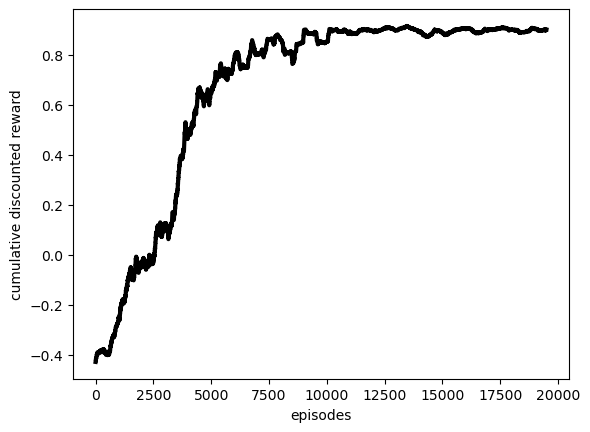

In [12]:
fig, ax = plt.subplots()
ax.plot(range(len(average_crewards)), average_crewards, '-', c='black', lw=3)

ax.set_ylabel("cumulative discounted reward")
ax.set_xlabel("episodes")


In [13]:
agent.store_q("./q_trained_100")

In [20]:
agent.reset()
pos = np.array([21, 120])
time_idx = rnd_state.randint(0, env.MAX_T)
obs = env.get_observation(pos, time_idx)
time_idx = 0#(time_idx + 1) % env.MAX_T
s = agent.update_state(obs) # update memory and compute olfactory state
trace = []
c_reward = 0.0
for t in range(H):
    a = agent.select_action()
    pos, r, terminated = env.make_move(pos, actions[a])
    print(pos, action_labels[a], s)
    obs = env.get_observation(pos, time_idx)
    time_idx = (time_idx + 1) % env.MAX_T
    s_prime = agent.update_state(obs)
    c_reward += r * (agent.gamma**t) if t > 0 else r
    trace.append((s, a, s_prime, r))
    if terminated:
        print("Converged in {} steps!".format(t))
        break
    s = s_prime


[ 21 119] left 1
[ 20 119] down 2
[ 20 118] left 3
[ 21 118] up 4
[ 22 118] up 5
[ 23 118] up 6
[ 24 118] up 7
[ 23 118] down 8
[ 23 117] left 9
[ 23 118] right 10
[ 24 118] up 11
[ 23 118] down 12
[ 23 119] right 13
[ 22 119] down 14
[ 21 119] down 15
[ 21 120] right 16
[ 20 120] down 17
[ 20 119] left 18
[ 19 119] down 19
[ 18 119] down 20
[ 18 120] right 21
[ 17 120] down 22
[ 18 120] up 23
[ 19 120] up 24
[ 18 120] down 25
[ 19 120] up 26
[ 18 120] down 27
[ 18 119] left 28
[ 18 118] left 29
[ 17 118] down 30
[ 17 119] right 31
[ 17 118] left 0
[ 17 117] left 0
[ 17 116] left 0
[ 17 115] left 0
[ 17 114] left 0
[ 17 113] left 0
[ 17 112] left 1
[ 16 112] down 2
[ 16 111] left 3
[ 17 111] up 4
[ 18 111] up 5
[ 19 111] up 6
[ 20 111] up 7
[ 19 111] down 8
[ 19 110] left 9
[ 19 111] right 10
[ 20 111] up 11
[ 19 111] down 12
[ 19 112] right 13
[ 18 112] down 14
[ 17 112] down 15
[ 17 113] right 16
[ 16 113] down 17
[ 16 112] left 18
[ 15 112] down 19
[ 14 112] down 20
[ 14 113] right 

In [17]:

num_up, num_down = 0, 0
for i in range(agent.Q.shape[0]):
    print("[--] state = {}\taction = {}\tQ-values = {}".format(i, action_labels[np.argmax(agent.Q[i])], agent.Q[i] ))
    if action_labels[np.argmax(agent.Q[i])] == 'up':
        num_up += 1
    if action_labels[np.argmax(agent.Q[i])] == 'down':
        num_down += 1

[--] state = 0	action = left	Q-values = [6.409577  6.3679466 6.3273907 7.7567906]
[--] state = 1	action = left	Q-values = [4.523277  4.43518   4.1225114 7.4693756]
[--] state = 2	action = down	Q-values = [3.982696  7.3974686 4.254145  4.051238 ]
[--] state = 3	action = left	Q-values = [4.211626  3.8901355 4.225493  7.332301 ]
[--] state = 4	action = up	Q-values = [7.255492  3.7734125 4.020088  3.8664823]
[--] state = 5	action = up	Q-values = [7.2338457 3.6119366 3.6186256 3.8315804]
[--] state = 6	action = up	Q-values = [7.113066  3.2299523 3.6950274 3.6489007]
[--] state = 7	action = up	Q-values = [7.0326467 3.4442477 3.1682527 3.5682557]
[--] state = 8	action = down	Q-values = [3.6283867 6.9131927 3.1010592 3.331006 ]
[--] state = 9	action = left	Q-values = [3.2869728 3.0854785 2.5720758 6.872413 ]
[--] state = 10	action = right	Q-values = [2.9730551 3.1753995 6.818488  3.0292192]
[--] state = 11	action = up	Q-values = [6.8093486 3.0046828 3.2247882 2.5474668]
[--] state = 12	action 

In [18]:
num_up, num_down

(36, 26)

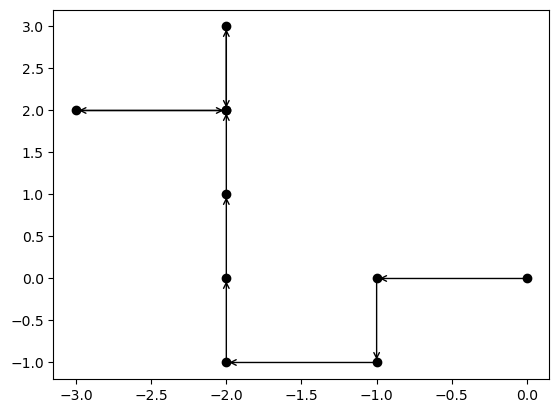

In [24]:
pos = np.array([0, 0])

path = [pos.copy()]
for i in range(1, agent.Q.shape[0]):
    pos += actions[np.argmax(agent.Q[i])]
#    print(actions[np.argmax(agent.Q[i])])
    path.append(pos.copy())

fig, ax = plt.subplots()
for i in range(10):#len(path)-1):
    ax.plot(path[i][1], path[i][0], 'o', c='black')
    ax.annotate("", xytext=(path[i][1], path[i][0]), xy=(path[i+1][1], path[i+1][0]), arrowprops=dict(arrowstyle='->'))
#    print(action_labels[np.argmin(agent.Q[i])])